# Sliding-window and global attention

A local head can only read neighbouring tokens in one layer. Marking a single token global changes which parts of a long sequence can exchange information in two layers.

Build the bidirectional local and global connection pattern used by Longformer. An explicit sparse calculation visits just the allowed keys. Both calculations here share projections for all tokens to isolate connectivity.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def report(columns, rows):
    frame = pd.DataFrame(rows, columns=columns)
    for column in frame.columns:
        if "error" in column.lower() or column == "Change in query norm":
            frame[column] = frame[column].map(lambda value: f"{value:.2e}")
    try:
        from IPython import get_ipython

        interactive = get_ipython() is not None
    except ImportError:
        interactive = False
    if interactive:
        from IPython.display import display

        display(frame.round(5))
    else:
        print(frame.round(5).to_string(index=False))


def softmax(logits, axis=-1):
    shifted = logits - np.max(logits, axis=axis, keepdims=True)
    weights = np.exp(shifted)
    return weights / weights.sum(axis=axis, keepdims=True)


def neighbours(i, length, radius, global_ids):
    if i in global_ids:
        return np.arange(length)
    local = np.arange(max(0, i - radius), min(length, i + radius + 1))
    return np.union1d(local, np.asarray(global_ids, dtype=int))


def sparse_attention(q, k, v, radius, global_ids):
    out = np.empty((len(q), v.shape[1]))
    mask = np.zeros((len(q), len(k)), dtype=bool)
    for i in range(len(q)):
        keys = neighbours(i, len(k), radius, global_ids)
        mask[i, keys] = True
        weights = softmax((q[i] @ k[keys].T) / np.sqrt(q.shape[1]))
        out[i] = weights @ v[keys]
    return out, mask

## Verify the output on a small sequence

The dense mask is built for visualisation and verification. A second, independently constructed dense reference checks both the chosen neighbours and their attention outputs.

In [2]:
rng = np.random.default_rng(17)
n, radius = 31, 2
q, k, v = rng.normal(size=(3, n, 8))
rows = []
maps = []
for name, glob in [("Window", []), ("Window + global", [0])]:
    out, connected = sparse_attention(q, k, v, radius, glob)
    ids = np.arange(n)
    reference = np.abs(ids[:, None] - ids[None, :]) <= radius
    reference[glob, :] = True
    reference[:, glob] = True
    assert np.array_equal(reference, connected)
    dense = softmax(np.where(reference, q @ k.T / np.sqrt(q.shape[1]), -np.inf)) @ v
    delta = np.max(np.abs(out - dense))
    assert delta < 1e-12
    reach = (connected.astype(int) @ connected.astype(int)) > 0
    rows.append((name, int(connected.sum()), n * n, connected[15].sum(), reach[15].sum(), delta))
    maps.extend([connected, reach])
report(
    [
        "Pattern",
        "Active scores",
        "All dense scores",
        "Direct keys at 15",
        "Reach after 2 layers",
        "Max abs error",
    ],
    rows,
)

,Pattern,Active scores,All dense scores,Direct keys at 15,Reach after 2 layers,Max abs error
0,Window,149,961,5,9,3.33e-16
1,Window + global,205,961,6,31,3.33e-16


## Inspect the information paths

A marked cell means a path exists under the mask. The amount of information a trained head sends along that path depends on its learned weights.

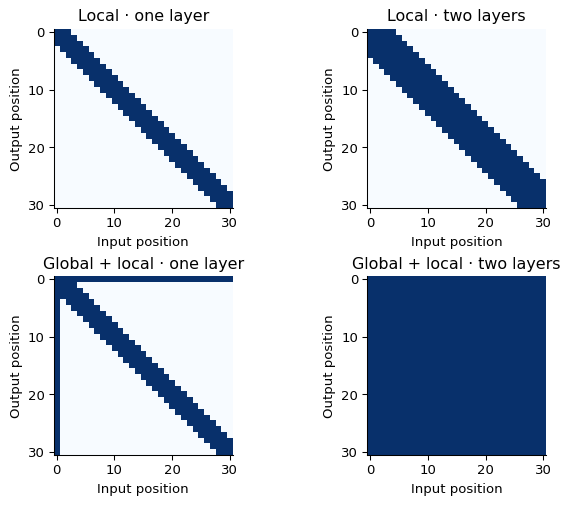

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(6.6, 5.2), layout="constrained")
for ax, m, title in zip(
    axes.flat,
    maps,
    [
        "Local · one layer",
        "Local · two layers",
        "Global + local · one layer",
        "Global + local · two layers",
    ],
):
    ax.imshow(m, origin="upper", interpolation="nearest", cmap="Blues", vmin=0, vmax=1)
    ax.set(xlabel="Input position", ylabel="Output position", title=title)
plt.show()

## Interpreting the result

A global token can read every input at layer one. A local token that reads it at layer two can therefore receive information from the full sequence. The visualisation constructs dense matrices only to verify this small case.

## Exercise

Move the global token from the beginning to the middle and compare the number of active scores with the two-layer reach.

## References

[Beltagy, Peters and Cohan (2020), Longformer](https://arxiv.org/abs/2004.05150)

[Vaswani et al. (2017), Attention Is All You Need](https://arxiv.org/abs/1706.03762)